# 06 · Algorithme génétique

Théorie complète : `docs/theory/03_genetic_algorithm.md`. Code : `optimizer/algorithms/genetic.py`.

**Codage.** Génotype $\sigma \in \mathfrak{S}_m$, phénotype $s = (\sigma(0), \dots, \sigma(n-1))$. Le gène $i < n$ a un sens **absolu** : c'est le qubit physique du qubit logique $i$.

**Une génération** (schéma du cours, $\mu = \lambda = N$) :
1. **Sélection** de $N/2$ couples :
   - tournoi : $k$ individus tirés avec remise, le $r$-ième meilleur gagne avec $p(1-p)^{r-1}$ ; pour $p = 1$, l'individu de rang global $r$ est choisi avec $\mathbb{P}(r) = \frac{(N-r+1)^k - (N-r)^k}{N^k}$ ;
   - roulette : $p_i = \dfrac{1/f_i}{\sum_j 1/f_j}$.
2. **Croisement** avec la probabilité $P_c$ ; sinon, les enfants sont des copies des parents.
3. **Mutation** de chaque enfant avec la probabilité $P_m$ : $\sigma' = \sigma \circ (a\ b)$, avec $a < n$.
4. **Évaluation** des enfants **nouveaux** seulement : un placement déjà évalué reprend son coût.
5. **Remplacement** $(\mu + \lambda)$ : $\mathcal{P}_{t+1} = \mathrm{best}_N(\mathcal{P}_t \cup \text{enfants})$.

**Croisements.** Points de coupe $a \le b$, ou masque $M$ pour le croisement uniforme.

| Opérateur | Définition | Ce qui est conservé |
|---|---|---|
| OX (cours) | $c_{[a,b]} = p^{(1)}_{[a,b]}$ ; positions $b+1, \dots, a-1$ remplies par $p^{(2)}$ lu à partir de $b+1$, privé du segment | segment : positions ; reste : **ordre** de $p^{(2)}$ |
| uniforme (cours) | hors masque : $p^{(1)}$ ; sur le masque : les éléments $p^{(1)}_M$ dans l'ordre de $p^{(2)}$ | hors masque : positions ; masque : ordre |
| PMX | $c_{[a,b]} = p^{(1)}_{[a,b]}$ ; hors segment $c_j = \varphi^{\kappa}(p^{(2)}_j)$, avec $\varphi(x) = p^{(2)}\big((p^{(1)})^{-1}(x)\big)$ | positions des deux parents, sauf conflits |
| CX | cycles de $\theta(j) = (p^{(1)})^{-1}(p^{(2)}_j)$, pris alternativement chez $p^{(1)}$ et $p^{(2)}$ | **toutes** les positions |

**Indicateurs.**

$$
h(c) = \frac1n \sum_{i<n} \mathbf{1}\big[c(i) \in \lbrace p^{(1)}(i), p^{(2)}(i) \rbrace\big] \ \ (\text{héritage positionnel}), \qquad
D = \frac{2}{N(N-1)} \sum_{a<b} \frac1n \sum_{i<n} \mathbf{1}\big[\sigma^{(a)}(i) \ne \sigma^{(b)}(i)\big] \ \ (\text{diversité})
$$

**Budget.** La population initiale coûte $N$ évaluations, puis chaque génération au plus $N$, d'où $G \approx (B - N)/N$, soit environ 9 générations pour $N = 20$. Les copies et les doublons ne coûtent rien.

**Options gratuites** (utilisation de $C$, comme `aco_filtered`) :
- population initiale : chaque individu est le meilleur selon $C$ de $R$ permutations aléatoires ;
- présélection : générer $\Lambda$ enfants et n'évaluer que les $N$ meilleurs selon $C$.

| Symbole | Code | Base |
|---|---|---|
| $N$ | `population_size` | 20 |
| sélection, $k$, $p$ | `selection`, `tournament_size`, `tournament_p` | tournoi, 2, 1 |
| croisement, $P_c$ | `crossover_operator`, `crossover_rate` | PMX, 0,8 |
| $P_m$ | `mutation_rate` | 0,1 |
| ordre des gènes | `construction_genes` | identité |
| $R$ | `initial_candidates` | 1 (population aléatoire) |
| $\Lambda / N$ | `preselection` | 1 (pas de présélection) |

In [1]:
import math
import os

import numpy as np
import pandas as pd
from scipy import stats  # test de Mann-Whitney

from goc.paths import RESULTS_ROOT, SOLUTIONS_ROOT
from optimizer import Problem, available_instances, distance_cost, history_frame, load_instance, load_results, results_frame, run_grid, save_results, write_solution_if_better
from optimizer.algorithms import genetic
from optimizer.construction import construction_order, interaction_weights
from optimizer.local_search import surrogate_local_optimum

In [2]:
# Réglages communs des graphiques : couleurs, polices, grilles.
import matplotlib as mpl
import matplotlib.pyplot as plt

# Palette de couleurs utilisée pour les séries (une couleur par algorithme ou par instance).
PALETTE = ["#3d72c4", "#d4692b", "#2a8a4f", "#c9443c", "#7a5cc2", "#8a8f98", "#c48a0a", "#2a9fb0", "#b04a8f"]
# Couleurs du cours : orange pour les qubits logiques, bleu pour les qubits physiques.
LOGICAL, LOGICAL_SOFT = "#d4692b", "#fdefe6"
PHYSICAL, PHYSICAL_SOFT = "#3d72c4", "#dfe8f5"
# Couleur selon la distance sur la puce : vert = voisins, jaune = distance 2, rouge = distance 3 ou plus.
DISTANCE_COLORS = {1: "#2a8a4f", 2: "#c48a0a", 3: "#c9443c"}
# Gris pour les textes secondaires et les grilles.
MUTED, GRID = "#656d76", "#e1e4e8"

# Application du style à tous les graphiques matplotlib du notebook.
mpl.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRID,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.frameon": False,
    "figure.dpi": 110,
})


def subplot_grid(count, cols=3, width=4.4, height=3.0):
    """Crée une grille de `count` petits graphiques (cols par ligne) et cache les cases inutilisées."""
    # Nombre de lignes nécessaires (division arrondie au supérieur).
    rows = -(-count // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * width, rows * height), squeeze=False)
    # Les cases en trop (dernière ligne incomplète) sont masquées.
    for ax in axes.ravel()[count:]:
        ax.set_visible(False)
    return fig, axes.ravel()[:count]

## Paramètres

Les exécutions sont enregistrées dans `results/genetic/` ; `RECOMPUTE = True` les refait. Les références, les fourmis et GRASP sont relus dans `results/comparison/` (notebook 99), avec le même budget et les mêmes graines.

In [3]:
INSTANCE_ID = 6
SEED = 0
BUDGET = 200
SEEDS = [0, 1, 2, 3, 4]
COMPARISON_INSTANCES = available_instances()
STUDY_INSTANCES = [3, 9]
STUDY_SEEDS = [0, 1, 2]
# Section 1 : nombre de couples de parents pour l'analyse des croisements (gratuite).
COUPLES = 500
REEVALUATIONS = 10
WORKERS = max(1, (os.cpu_count() or 2) - 4)
RECOMPUTE = False
CACHE_DIR = RESULTS_ROOT / "genetic"
REFERENCE_DIR = RESULTS_ROOT / "comparison"
GROUP = "Groupe0"
SOLUTIONS_DIR = SOLUTIONS_ROOT

BASE = {"population_size": 20, "selection": "tournament", "tournament_size": 2, "tournament_p": 1.0, "crossover_operator": "pmx",
        "crossover_rate": 0.8, "mutation_rate": 0.1, "construction_genes": False, "initial_candidates": 1, "preselection": 1}

In [4]:
def cached_grid(name, algorithms, instance_ids, seeds, budget):
    """Lance run_grid, ou relit le résultat déjà enregistré dans CACHE_DIR/<name>.jsonl."""
    path = CACHE_DIR / f"{name}.jsonl"
    if path.exists() and not RECOMPUTE:
        results = load_results(path)
        print(f"Loaded {len(results)} runs from {path}")
        return results
    results = run_grid(algorithms, instance_ids, seeds, budget, workers=WORKERS)
    save_results(results, path)
    return results


def display_table(frame, value="best_cost"):
    """Pour chaque algorithme et instance : « moyenne ± écart-type (meilleur) » de b_B sur les graines."""
    cells = frame.groupby(["algorithm", "instance_id"], sort=False)[value].agg(lambda s: f"{s.mean():.1f} ± {s.std(ddof=0):.1f} ({s.min():g})")
    return cells.unstack("instance_id").rename(columns=lambda c: f"inst. {c}")

## 1. Les croisements (sans évaluation)

### 1.1 Vérification sur les exemples du cours

- **OX** : $A = 35\vert 7124 \vert 869$ et $B = 19\vert 2346 \vert 875$ doivent donner $B' = 367124859$ et $A' = 712346895$.
- **Uniforme de permutations** : $12345$ et $54321$ avec le masque $11010$ doivent donner $42315$ et $54123$.

In [5]:
A, B = np.array([3, 5, 7, 1, 2, 4, 8, 6, 9]) - 1, np.array([1, 9, 2, 3, 4, 6, 8, 7, 5]) - 1
print("OX      B' =", genetic.ox(A, B, 2, 5) + 1, "  A' =", genetic.ox(B, A, 2, 5) + 1)
p1, p2, mask = np.arange(5), np.arange(5)[::-1], np.array([1, 1, 0, 1, 0], bool)
print("uniform c1 =", genetic.uniform_permutation(p1, p2, mask) + 1, "  c2 =", genetic.uniform_permutation(p2, p1, ~mask) + 1)

OX      B' = [3 6 7 1 2 4 8 5 9]   A' = [7 1 2 3 4 6 8 9 5]
uniform c1 = [4 2 3 1 5]   c2 = [5 4 1 2 3]


### 1.2 Ce que chaque croisement conserve

Les parents sont des **optima locaux de $C$** (de bons placements, différents les uns des autres), et on mesure `COUPLES` croisements par opérateur. Pour chaque opérateur :
- $\bar h$ : héritage positionnel moyen ;
- distance de Hamming moyenne de l'enfant à son parent le plus proche, sur les $n$ gènes utiles ;
- $\Delta C$ moyen : $C(\text{enfant})$ moins la moyenne de $C$ des deux parents ;
- part des enfants identiques à un parent.

**Ce qu'on attend.** Un bon croisement pour ce problème a un $h$ élevé (il transmet des positions) et un $\Delta C$ faible (il casse peu de « briques », c'est-à-dire de qubits qui interagissent placés côte à côte). Mais s'il produit trop souvent des copies, il n'explore plus.

In [6]:
def crossover_profile(instance_id, couples, seed=0):
    """Statistiques des enfants de chaque opérateur, pour des parents optima locaux de C."""
    inst = load_instance(instance_id)
    weights = interaction_weights(inst)
    rng = np.random.default_rng(seed)
    parents = [surrogate_local_optimum(inst, weights, rng.permutation(inst.m))[0] for _ in range(60)]
    order = np.array(construction_order(weights) + list(range(inst.n, inst.m)))
    rows = []
    for label, operator, reordered in [("PMX", "pmx", False), ("CX", "cx", False), ("OX", "ox", False), ("uniform", "uniform", False), ("PMX, construction order", "pmx", True)]:
        h, distance, delta, copies = [], [], [], 0
        for _ in range(couples):
            i, j = rng.choice(len(parents), size=2, replace=False)
            x, y = parents[i], parents[j]
            g = order if reordered else np.arange(inst.m)
            c, _ = genetic.crossover(x[g], y[g], operator, rng)
            child = np.empty(inst.m, dtype=int)
            child[g] = c
            h.append(genetic.inheritance(child, x, y, inst.n))
            distance.append(min(np.mean(child[: inst.n] != x[: inst.n]), np.mean(child[: inst.n] != y[: inst.n])))
            delta.append(distance_cost(inst, child[: inst.n]) - (distance_cost(inst, x[: inst.n]) + distance_cost(inst, y[: inst.n])) / 2)
            copies += distance[-1] == 0
        rows.append({"instance": instance_id, "crossover": label, "mean h": round(float(np.mean(h)), 3), "distance to nearest parent": round(float(np.mean(distance)), 3), "mean ΔC": round(float(np.mean(delta)), 1), "copies of a parent": f"{copies / couples:.0%}"})
    return rows


crossover_table = pd.DataFrame([row for i in sorted({INSTANCE_ID, *STUDY_INSTANCES}) for row in crossover_profile(i, COUPLES)]).set_index(["instance", "crossover"])
crossover_table

mean h  distance to nearest parent  mean ΔC  \
instance crossover                                                              
3        PMX                       0.855                       0.298     15.5   
         CX                        1.000                       0.207      8.6   
         OX                        0.606                       0.437     25.3   
         uniform                   0.665                       0.415     18.2   
         PMX, construction order   0.847                       0.300     13.8   
6        PMX                       0.853                       0.309     22.1   
         CX                        1.000                       0.211     15.2   
         OX                        0.579                       0.464     32.8   
         uniform                   0.645                       0.441     33.3   
         PMX, construction order   0.859                       0.303     15.5   
9        PMX                       0.848                       0.331     18.3   
         CX                        1.000                       0.229     25.7   
         OX                        0.558                       0.512     14.9   
         uniform                   0.611                       0.460     39.8   
         PMX, construction order   0.840                       0.350     20.0   

                                 copies of a parent  
instance crossover                                   
3        PMX                                    14%  
         CX                                     26%  
         OX                                     11%  
         uniform                                 3%  
         PMX, construction order                16%  
6        PMX                                    10%  
         CX                                     21%  
         OX                                      6%  
         uniform                                 0%  
         PMX, construction order                 7%  
9        PMX                                     3%  
         CX                                     10%  
         OX                                      2%  
         uniform                                 0%  
         PMX, construction order                 2%

## 2. Une exécution complète (base, instance `INSTANCE_ID`)

À gauche : $f$ des enfants évalués à chaque génération, meilleur individu et moyenne de la population. À droite : la diversité $D$ et l'héritage $\bar h$ des enfants croisés. La convergence de la population se lit par $D \to 0$ : la population devient un ensemble de clones, et le croisement ne produit plus de nouveauté.

Loaded 1 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\genetic\single_run_instance_6.jsonl
best fitness 34 ; 14 generations ; 200 evaluations ; 14.8 s


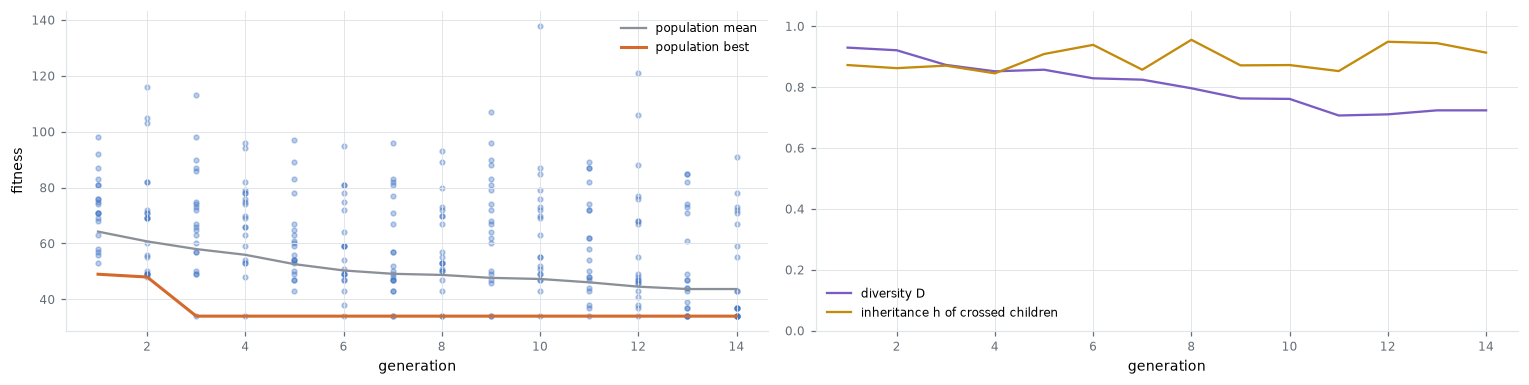

In [7]:
single = cached_grid(f"single_run_instance_{INSTANCE_ID}", {"genetic": (genetic.run, BASE)}, [INSTANCE_ID], [SEED], BUDGET)[0]
generations = pd.DataFrame(single.trace["generations"])
print(f"best fitness {single.best_cost} ; {len(generations)} generations ; {single.evaluations} evaluations ; {single.seconds:.1f} s")


def plot_genetic_run(generations):
    """Enfants évalués, meilleur et moyenne de la population ; diversité et héritage, par génération."""
    fig, (left, right) = plt.subplots(1, 2, figsize=(14, 3.6))
    for _, row in generations.iterrows():
        left.scatter([row["generation"]] * len(row["children_costs"]), row["children_costs"], s=10, color=PHYSICAL, alpha=0.35)
    left.plot(generations["generation"], generations["population_mean"], color=PALETTE[5], label="population mean")
    left.plot(generations["generation"], generations["population_best"], color=LOGICAL, linewidth=2, label="population best")
    left.set_xlabel("generation")
    left.set_ylabel("fitness")
    left.legend()
    right.plot(generations["generation"], generations["diversity"], color=PALETTE[4], label="diversity D")
    right.plot(generations["generation"], generations["inheritance"], color=PALETTE[6], label="inheritance h of crossed children")
    right.set_ylim(0, 1.05)
    right.set_xlabel("generation")
    right.legend()
    fig.tight_layout()
    return fig


plot_genetic_run(generations);

## 3. Effet des paramètres (instances 3 et 9, 3 graines, $B = 200$)

Un seul paramètre varie autour de la base. Tableau : `moyenne ± écart-type (meilleur)` de $b_B$ ; figure : convergence moyenne $b_t$.

**Résolution.** Avec 3 graines, un écart d'environ ±5 sur l'instance 3 et d'environ ±2 sur l'instance 9 n'est pas significatif (notebook 04).

In [8]:
def plot_study(results, title):
    """Convergence moyenne b_t (moyenne sur les graines) de chaque réglage, une colonne par instance."""
    order = list(dict.fromkeys(r.algorithm for r in results))
    instance_ids = sorted({r.instance_id for r in results})
    fig, axes = plt.subplots(1, len(instance_ids), figsize=(5.4 * len(instance_ids), 3.3), squeeze=False)
    for ax, instance_id in zip(axes[0], instance_ids):
        history = history_frame([r for r in results if r.instance_id == instance_id])
        for color, algorithm in zip(PALETTE, order):
            curves = history[history["algorithm"] == algorithm].pivot_table(index="evaluation", columns="seed", values="best").ffill()
            ax.plot(curves.index, curves.mean(axis=1), color=color, label=algorithm, linewidth=1.5)
        ax.set_title(f"Instance {instance_id}")
        ax.set_xlabel("evaluations t", fontsize=8)
        ax.set_ylabel("mean best fitness b_t", fontsize=8)
        ax.legend(fontsize=7)
    fig.suptitle(title, y=1.02)
    fig.tight_layout()
    return fig


def study(name, settings):
    """Une exécution par réglage (dictionnaire de paramètres modifiant BASE), instance et graine."""
    algorithms = {label: (genetic.run, {**BASE, **changes}) for label, changes in settings.items()}
    return cached_grid(f"study_{name}", algorithms, STUDY_INSTANCES, STUDY_SEEDS, BUDGET)

### 3.1 Croisement

Les croisements qui conservent les positions (CX, PMX) sont adaptés au sens absolu des gènes, mais CX explore peu. Ranger les gènes dans l'ordre de construction $i_1, \dots, i_n$ rapproche dans le chromosome les qubits qui interagissent. D'après le théorème des schémas, cela réduit la longueur $\delta(H)$ des « briques », et donc leur risque d'être coupées par un croisement à segment.

Loaded 30 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\genetic\study_crossover.jsonl


instance_id,inst. 3,inst. 9
algorithm,,
PMX,137.0 ± 2.4 (134),86.7 ± 8.5 (75)
CX,138.3 ± 7.4 (128),84.3 ± 5.3 (78)
OX,134.7 ± 4.6 (130),84.7 ± 6.2 (78)
uniform,132.0 ± 7.1 (126),88.3 ± 9.3 (79)
PMX + order,134.0 ± 9.9 (120),88.0 ± 9.4 (79)


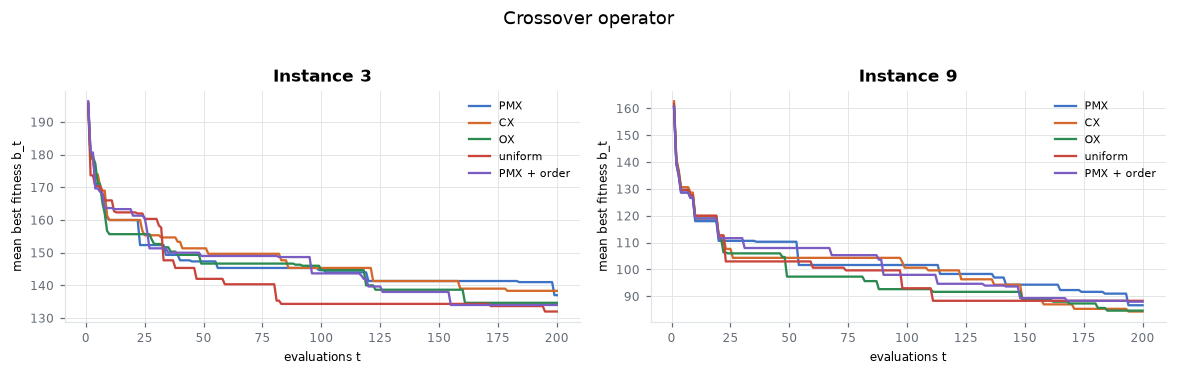

In [9]:
crossover_study = study("crossover", {"PMX": {}, "CX": {"crossover_operator": "cx"}, "OX": {"crossover_operator": "ox"}, "uniform": {"crossover_operator": "uniform"}, "PMX + order": {"construction_genes": True}})
display(display_table(results_frame(crossover_study)))
plot_study(crossover_study, "Crossover operator");

### 3.2 Sélection

- **Roulette** : $p_{\mathrm{meilleur}} / p_{\mathrm{pire}} = f_{\mathrm{pire}} / f_{\mathrm{meilleur}}$, proche de 1 quand les coûts sont proches, donc une pression presque nulle.
- **Tournoi déterministe** : il ne dépend que des rangs. Avec $N = 20$, le meilleur individu est choisi avec la probabilité $1 - (19/20)^k$, soit 9,8 % pour $k = 2$ et 18,5 % pour $k = 4$, contre 5 % au hasard.

Loaded 18 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\genetic\study_selection.jsonl


instance_id,inst. 3,inst. 9
algorithm,,
tournament k=2,140.3 ± 2.6 (138),83.3 ± 11.3 (73)
tournament k=4,131.3 ± 8.4 (120),78.7 ± 13.9 (62)
roulette,135.7 ± 5.9 (131),97.0 ± 2.2 (94)


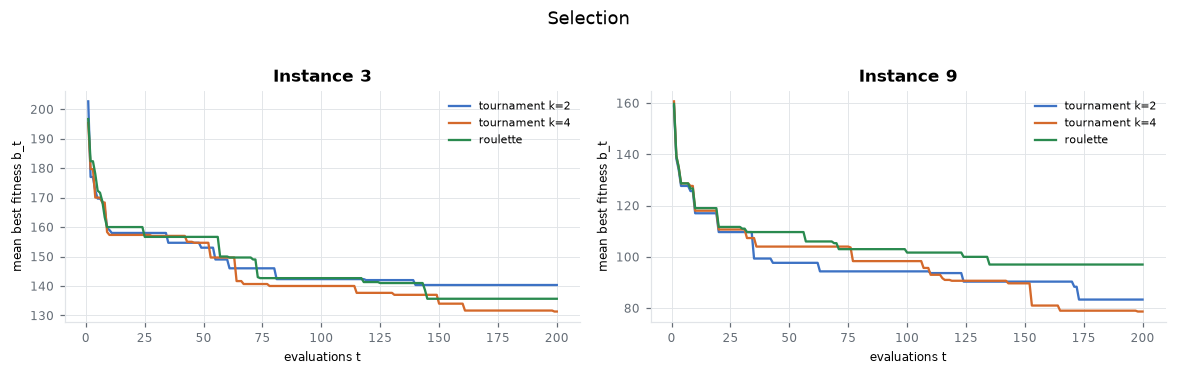

In [10]:
selection_study = study("selection", {"tournament k=2": {}, "tournament k=4": {"tournament_size": 4}, "roulette": {"selection": "roulette"}})
display(display_table(results_frame(selection_study)))
plot_study(selection_study, "Selection");

### 3.3 Mutation $P_m$

Nombre attendu d'enfants nouveaux par génération :

$$
\mathbb{E}[\text{nouveaux}] \le N\,\big[P_c + (1 - P_c)\,P_m\big]
$$

Il vaut 16,0 pour $P_m = 0$ et 18,4 pour $P_m = 0{,}6$. Au-delà du nombre de nouveaux, la mutation entretient surtout la diversité $D$ ; avec $P_m = 0$, une fois la population convergée, plus rien de nouveau n'apparaît.

Loaded 24 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\genetic\study_mutation.jsonl


instance_id,inst. 3,inst. 9
algorithm,,
P_m=0,139.0 ± 8.6 (128),91.0 ± 7.8 (80)
P_m=0.1,137.0 ± 2.9 (134),94.3 ± 5.2 (87)
P_m=0.3,139.3 ± 0.9 (138),88.3 ± 13.2 (78)
P_m=0.6,132.0 ± 8.0 (121),82.0 ± 6.2 (75)


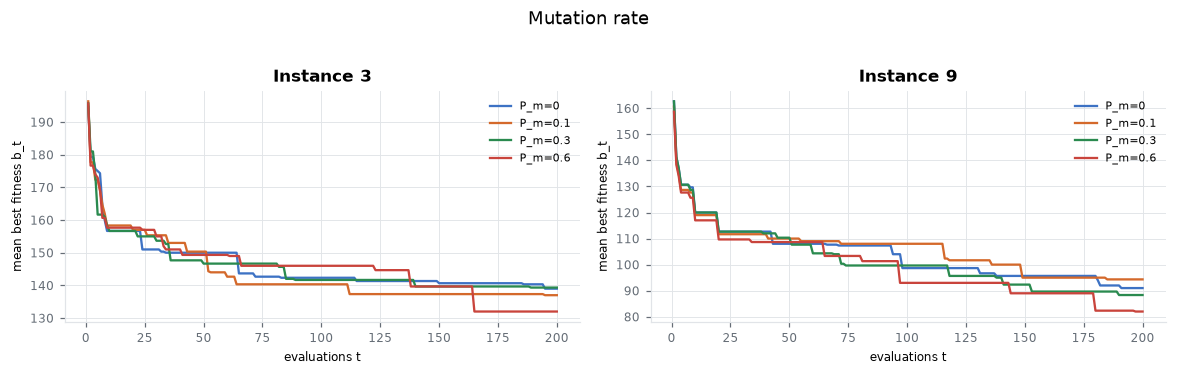

In [11]:
mutation_study = study("mutation", {"P_m=0": {"mutation_rate": 0.0}, "P_m=0.1": {}, "P_m=0.3": {"mutation_rate": 0.3}, "P_m=0.6": {"mutation_rate": 0.6}})
display(display_table(results_frame(mutation_study)))
plot_study(mutation_study, "Mutation rate");

### 3.4 Taille de la population $N$

Le nombre de générations vaut $G \approx (B - N)/N$, soit 19, 9 et 4 pour $N$ = 10, 20 et 40. Une grande population est plus diverse mais n'a presque pas de générations pour évoluer ; une petite évolue plus longtemps mais converge vite ($D \to 0$).

Loaded 18 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\genetic\study_population.jsonl


instance_id,inst. 3,inst. 9
algorithm,,
N=10,123.7 ± 0.5 (123),76.0 ± 11.2 (61)
N=20,138.7 ± 3.3 (135),81.7 ± 9.5 (69)
N=40,137.0 ± 6.5 (128),90.0 ± 13.6 (71)


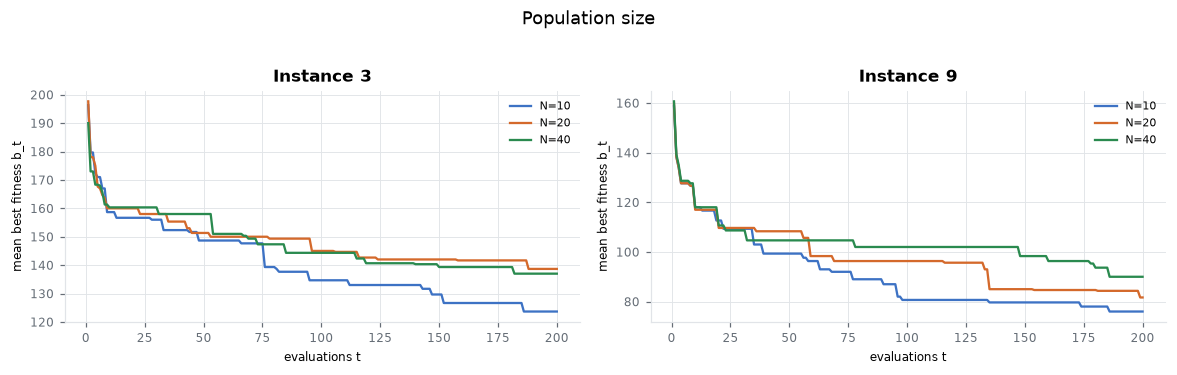

In [12]:
population_study = study("population", {"N=10": {"population_size": 10}, "N=20": {}, "N=40": {"population_size": 40}})
display(display_table(results_frame(population_study)))
plot_study(population_study, "Population size");

### 3.5 Utilisation gratuite de $C$

- **Aucune** : population aléatoire, chaque enfant évalué.
- **Présélection** : $\Lambda = 5N$ enfants générés, les $N$ meilleurs selon $C$ évalués.
- **Population initiale filtrée et présélection** : en plus, chaque individu initial est le meilleur selon $C$ de 200 permutations.

On attend un gain là où $\rho_S(C, f)$ est élevé (instance 9).

Loaded 18 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\genetic\study_filter.jsonl


instance_id,inst. 3,inst. 9
algorithm,,
none,133.7 ± 1.2 (132),96.0 ± 3.7 (91)
preselection,128.7 ± 6.1 (121),73.0 ± 2.2 (70)
initial + preselection,125.0 ± 2.9 (121),71.0 ± 4.3 (67)


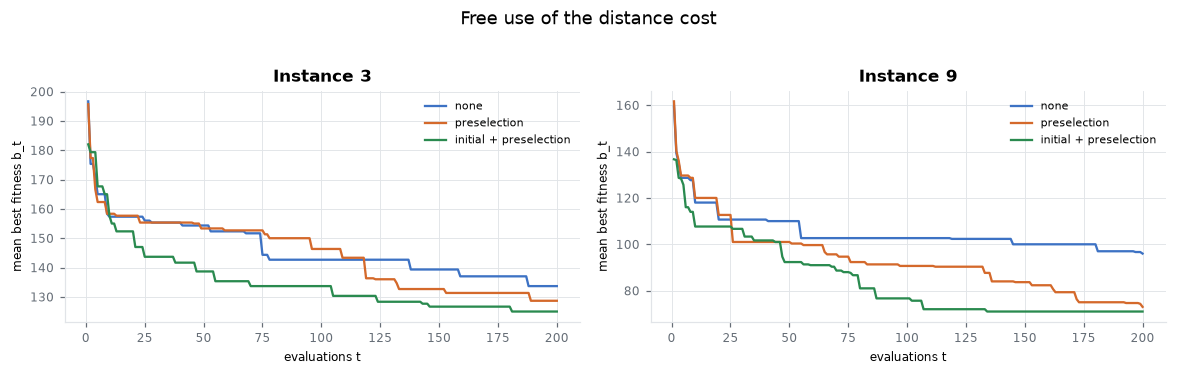

In [13]:
filter_study = study("filter", {"none": {}, "preselection": {"preselection": 5}, "initial + preselection": {"initial_candidates": 200, "preselection": 5}})
display(display_table(results_frame(filter_study)))
plot_study(filter_study, "Free use of the distance cost");

## 4. Comparaison sur les 9 instances (5 graines, $B = 200$)

Le réglage retenu prend $N = 10$, qui fait $G \approx 19$ générations au lieu de 9. C'est la meilleure taille de population de l'étude 3.4 sur les deux instances, avec un écart supérieur à la résolution. Le reste est la base. Deux variantes :
- `genetic` : sans utilisation de $C$ (algorithme génétique « pur », comme dans le cours) ;
- `genetic_filtered` : population initiale filtrée par $C$ ($R = 200$) et présélection des enfants ($\Lambda = 5N$), l'option la plus favorable de l'étude 3.5.

Comme $N$ a été choisi sur les instances 3 et 9, le résultat sur ces deux instances est légèrement favorisé ; les 7 autres servent de validation.

On compare à `aco_filtered`, `grasp` et aux trois références, relus dans `results/comparison/`.

In [14]:
# Réglage retenu après les études de la section 3 (identique à celui du notebook 99).
TUNED = {**BASE, **{"population_size": 10}}
COMPARISON = {
    "genetic": (genetic.run, TUNED),
    "genetic_filtered": (genetic.run, {**TUNED, "initial_candidates": 200, "preselection": 5}),
}
comparison = cached_grid("comparison", COMPARISON, COMPARISON_INSTANCES, SEEDS, BUDGET)
others = []
for name in ["identity", "random_search", "surrogate_filtered", "aco_filtered", "grasp"]:
    path = REFERENCE_DIR / f"{name}.jsonl"
    if path.exists():
        others += [r for r in load_results(path) if r.evaluations == BUDGET and r.seed in SEEDS and r.instance_id in COMPARISON_INSTANCES]
ORDER = ["identity", "random_search", "surrogate_filtered", "aco_filtered", "grasp", "genetic", "genetic_filtered"]
frame = results_frame(comparison + others)
display_table(frame).reindex(ORDER)

[9/90] 52 s | last: genetic, instance 4, seed 3 -> 38


[18/90] 115 s | last: genetic, instance 6, seed 2 -> 38


[27/90] 138 s | last: genetic, instance 2, seed 3 -> 75


[36/90] 166 s | last: genetic_filtered, instance 1, seed 0 -> 30


[45/90] 180 s | last: genetic, instance 9, seed 2 -> 68


[54/90] 215 s | last: genetic_filtered, instance 4, seed 3 -> 35


[63/90] 274 s | last: genetic_filtered, instance 6, seed 2 -> 28


[72/90] 303 s | last: genetic_filtered, instance 7, seed 1 -> 54


[81/90] 325 s | last: genetic_filtered, instance 8, seed 0 -> 24


[90/90] 336 s | last: genetic_filtered, instance 9, seed 4 -> 75


instance_id,inst. 1,inst. 2,inst. 3,inst. 4,inst. 5,inst. 6,inst. 7,inst. 8,inst. 9
algorithm,,,,,,,,,
identity,57.0 ± 0.0 (57),59.0 ± 0.0 (59),141.0 ± 0.0 (141),62.0 ± 0.0 (62),332.2 ± 1.0 (331),78.2 ± 2.4 (77),107.0 ± 0.0 (107),66.8 ± 1.0 (66),137.0 ± 0.0 (137)
random_search,38.4 ± 2.1 (36),90.2 ± 4.5 (86),139.4 ± 5.2 (132),42.4 ± 0.8 (42),334.0 ± 9.0 (323),39.6 ± 3.7 (35),73.6 ± 7.2 (63),40.0 ± 3.8 (34),98.2 ± 3.5 (93)
surrogate_filtered,34.8 ± 1.7 (33),75.8 ± 2.9 (71),140.0 ± 2.2 (137),38.8 ± 1.5 (36),332.0 ± 4.9 (326),33.8 ± 2.1 (31),64.6 ± 6.3 (57),38.4 ± 2.4 (34),90.2 ± 10.4 (79)
aco_filtered,30.0 ± 0.9 (29),59.0 ± 0.0 (59),128.0 ± 5.2 (122),33.8 ± 2.4 (30),323.0 ± 4.4 (317),25.0 ± 0.0 (25),25.2 ± 2.9 (22),21.6 ± 2.0 (19),54.4 ± 2.8 (51)
grasp,29.8 ± 1.5 (27),59.0 ± 0.0 (59),136.0 ± 6.6 (127),34.8 ± 1.7 (32),323.4 ± 3.3 (317),25.0 ± 0.0 (25),22.0 ± 0.0 (22),18.0 ± 0.6 (17),50.2 ± 2.9 (48)
genetic,31.4 ± 2.9 (27),76.8 ± 5.9 (71),132.6 ± 5.7 (124),35.8 ± 1.6 (34),328.4 ± 6.2 (318),36.2 ± 3.1 (31),59.6 ± 8.5 (49),39.8 ± 1.9 (38),79.8 ± 8.8 (68)
genetic_filtered,30.0 ± 0.9 (29),66.2 ± 8.8 (59),131.2 ± 2.8 (128),33.0 ± 1.7 (31),322.2 ± 4.9 (318),31.4 ± 3.6 (27),43.0 ± 7.9 (31),29.0 ± 3.7 (24),67.2 ± 9.2 (51)


Rang de la moyenne de $b_B$ sur chaque instance (1 = meilleure), puis rang moyen :

In [15]:
means = frame.groupby(["algorithm", "instance_id"])["best_cost"].mean().unstack().reindex(ORDER)
ranks = means.rank(axis=0, method="min").rename(columns=lambda c: f"inst. {c}")
ranks["mean rank"] = ranks.mean(axis=1).round(2)
ranks.sort_values("mean rank")

instance_id,inst. 1,inst. 2,inst. 3,inst. 4,inst. 5,inst. 6,inst. 7,inst. 8,inst. 9,mean rank
algorithm,,,,,,,,,,
aco_filtered,2.0,1.0,1.0,2.0,2.0,1.0,2.0,2.0,2.0,1.67
grasp,1.0,1.0,4.0,3.0,3.0,1.0,1.0,1.0,1.0,1.78
genetic_filtered,2.0,4.0,2.0,1.0,1.0,3.0,3.0,3.0,3.0,2.44
genetic,4.0,6.0,3.0,4.0,4.0,5.0,4.0,5.0,4.0,4.33
surrogate_filtered,5.0,5.0,6.0,5.0,5.0,4.0,5.0,4.0,5.0,4.89
random_search,6.0,7.0,5.0,6.0,7.0,6.0,6.0,6.0,6.0,6.11
identity,7.0,1.0,7.0,7.0,6.0,7.0,7.0,7.0,7.0,6.22


**Tests de Mann-Whitney unilatéraux** (définition dans le notebook 04). Chaque case donne la *p-value* de « la ligne est meilleure que la colonne » ; $p < 0{,}05$ indique un avantage fiable.

In [16]:
def significance(frame, algorithm, others):
    """p-values de Mann-Whitney « algorithm est meilleur que other », par instance (lignes) et adversaire (colonnes)."""
    rows = {}
    for instance_id in sorted(frame["instance_id"].unique()):
        subset = frame[frame["instance_id"] == instance_id]
        target = subset.loc[subset["algorithm"] == algorithm, "best_cost"]
        rows[f"inst. {instance_id}"] = {other: stats.mannwhitneyu(target, subset.loc[subset["algorithm"] == other, "best_cost"], alternative="less").pvalue for other in others}
    return pd.DataFrame(rows).T.round(4)


best_genetic = means.loc[["genetic", "genetic_filtered"]].mean(axis=1).idxmin()
print(f"{best_genetic} better than ...")
display(significance(frame, best_genetic, ["random_search", "surrogate_filtered", "aco_filtered", "grasp"]))
print(f"... better than {best_genetic}")
display(pd.DataFrame({other: significance(frame, other, [best_genetic])[best_genetic] for other in ["aco_filtered", "grasp"]}))

genetic_filtered better than ...


,random_search,surrogate_filtered,aco_filtered,grasp
inst. 1,0.0058,0.0057,0.5445,0.5000
inst. 2,0.0057,0.0706,0.9806,0.9806
inst. 3,0.0229,0.0058,0.8548,0.2310
inst. 4,0.0046,0.0056,0.2596,0.0994
inst. 5,0.0297,0.0181,0.4160,0.3352
inst. 6,0.0106,0.2003,0.9981,0.9981
inst. 7,0.0040,0.0060,0.9968,0.9981
inst. 8,0.0079,0.0079,0.9940,0.9970
inst. 9,0.0040,0.0040,0.9719,0.9900


... better than genetic_filtered


,aco_filtered,grasp
inst. 1,0.5445,0.5867
inst. 2,0.0354,0.0354
inst. 3,0.1988,0.8279
inst. 4,0.8049,0.9331
inst. 5,0.6643,0.7384
inst. 6,0.0037,0.0037
inst. 7,0.0060,0.0037
inst. 8,0.0106,0.0056
inst. 9,0.0448,0.0172


## 5. Meilleures solutions

Pour chaque instance, on prend le meilleur $s^{\mathrm{bs}}$ des variantes génétiques, on le réévalue `REEVALUATIONS` fois, et le fichier solution n'est écrit que s'il bat celui déjà présent.

In [17]:
rows = []
for instance_id in COMPARISON_INSTANCES:
    best = min((r for r in comparison if r.instance_id == instance_id), key=lambda r: r.best_cost)
    checks = Problem(load_instance(instance_id)).fitness_samples(best.best_mapping, REEVALUATIONS)
    cost = min(best.best_cost, min(checks))
    path, written, previous = write_solution_if_better(best.best_mapping, cost, instance_id, group=GROUP, directory=SOLUTIONS_DIR)
    rows.append({
        "instance": instance_id, "algorithm": best.algorithm, "seed": best.seed,
        "cost during search": best.best_cost, "re-evaluation mean": round(float(np.mean(checks)), 2),
        "re-evaluation std": round(float(np.std(checks)), 2),
        "file status": "written" if written else f"kept (existing cost {previous:g})",
        "mapping": " ".join(map(str, best.best_mapping)),
    })
best_solutions = pd.DataFrame(rows).set_index("instance")
best_solutions

,algorithm,seed,cost during search,re-evaluation mean,re-evaluation std,file status,mapping
instance,,,,,,,
1,genetic,1,27,27.0,0.00,kept (existing cost 25),12 1 11 4 6 5 7 0 15 8 10 3
2,genetic_filtered,0,59,59.0,0.00,kept (existing cost 59),9 8 7 6 5 10 11 4 3 12 13 14 15 0 1 2
3,genetic,3,124,131.8,6.88,kept (existing cost 115),9 10 3 2 12 14 13 0 1 15
4,genetic_filtered,0,31,31.8,0.98,kept (existing cost 30),7 12 5 8 11 6 9 1 17 18 4 15 13 2 16 0 10 3 14
5,genetic,0,318,320.6,1.69,kept (existing cost 316),11 10 15 18 8 7 1 2 5 17 16 13
6,genetic_filtered,0,27,27.0,0.00,kept (existing cost 25),5 8 13 12 16 17 18 15 2 3 6 11 9 10
7,genetic_filtered,4,31,31.0,0.00,kept (existing cost 22),18 23 21 24 25 22 19 16 9 15 13 6 7 14 11 8 3 ...
8,genetic_filtered,0,24,27.2,3.92,kept (existing cost 17),1 4 22 19 11 9 17 18 10 12 14 15 26 8 13 21 6 ...
9,genetic_filtered,3,51,51.0,0.00,kept (existing cost 48),14 7 15 16 19 20 26 25 23 21 12 17 10 6 4 0 8 ...


## Conclusions

_Exécution du 22/11/2026 : $B = 200$, 5 graines, 9 instances, $N = 10$ (environ 19 générations). Les références, `aco_filtered` et `grasp` sont relus du notebook 99._

### Résultat principal

| | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|
| `aco_filtered` | 30,0 | **59,0** | **128,0** | 33,8 | 323,0 | **25,0** | 25,2 | 21,6 | 54,4 |
| `grasp` | **29,8** | **59,0** | 136,0 | 34,8 | 323,4 | **25,0** | **22,0** | **18,0** | **50,2** |
| `genetic_filtered` | 30,0 | 66,2 | 131,2 | **33,0** | **322,2** | 31,4 | 43,0 | 29,0 | 67,2 |
| `genetic` | 31,4 | 76,8 | 132,6 | 35,8 | 328,4 | 36,2 | 59,6 | 39,8 | 79,8 |

Rangs moyens : `aco_filtered` 1,67, `grasp` 1,78, `genetic_filtered` 2,44, `genetic` 4,33.

- **`genetic_filtered` bat les références.** Il bat significativement `random_search` sur les 9 instances et `surrogate_filtered` sur 7.
- **Il est 1er sur les instances 4 et 5**, mais sans différence significative avec les fourmis ou GRASP.
- **Il est significativement battu par les fourmis et par GRASP sur 2, 6, 7, 8 et 9.**
- **Sans utilisation de $C$, `genetic` est faible** : à peine meilleur que `surrogate_filtered` en rang moyen.

### Interprétation

- **Information locale.** Les fourmis et GRASP **construisent** chaque placement avec $g_t$ ; l'algorithme génétique ne fait que **recombiner** des placements existants, sans information sur la puce. Sur les instances où $C$ est fiable (2, 6 à 9), partir de placements construits pour minimiser $C$ donne une avance que 19 générations ne rattrapent pas. Sur l'instance 7, par exemple, on obtient 43,0 contre 22,0 pour GRASP.
- **Instances où $C$ guide mal** (3, 4, 5). Cette avance disparaît, et la sélection sur $f$ suffit à rester au niveau des meilleurs : 1er sur 4 et 5, 2e sur 3.
- **Budget.** Avec $G \approx (B - N)/N$, un algorithme génétique a très peu de générations. L'étude 3.4 le confirme : $N = 10$ (19 générations) fait mieux que $N = 20$ (9) et $N = 40$ (4).
- **Utilisation de $C$.** Elle est indispensable. La présélection des enfants donne 73,0 contre environ 88 sur l'instance 9 dans l'étude 3.5, et 67,2 contre 79,8 dans la comparaison. Elle joue le même rôle que le filtrage des fourmis.

### Croisements (section 1.2 et étude 3.1)

Les mesures confirment la théorie :
- **CX** conserve toutes les positions ($\bar h = 1$), mais explore le moins : distance moyenne à son parent le plus proche d'environ 0,21, et 10 à 26 % de copies pures d'un parent.
- **OX et le croisement uniforme** ne conservent qu'environ 60 % des positions, et cassent le plus de « briques » ($\Delta C$ le plus grand sur les instances 3 et 6).
- **PMX** est intermédiaire.
- **Ranger les gènes dans l'ordre de construction** réduit $\Delta C$ pour PMX sur les instances 3 et 6, ce qui confirme le théorème des schémas.

Mais en fitness, aucune différence entre croisements ne dépasse la résolution de l'étude (environ ±5 sur l'instance 3, environ ±7 sur l'instance 9) : avec 19 générations au plus, le choix du croisement compte moins que le budget et l'utilisation de $C$.

### Sélection et mutation

- **Sélection.** La roulette est la moins bonne sur l'instance 9 (97,0). Les coûts y vont d'environ 50 à 100 : le rapport des probabilités extrêmes vaut au plus 2, donc la pression de sélection est faible. Le tournoi, qui ne dépend que des rangs, est préférable.
- **Mutation.** $P_m$ n'a pas d'effet net. Grâce au remplacement sans doublons, la diversité reste élevée ($D \approx 0{,}7$ en fin d'exécution) sans avoir besoin de mutation.

### Point de conception : les doublons

Une première version gardait les $N$ meilleurs individus **avec** leurs doublons : la population devenait une suite de copies du meilleur ($D = 0$ dès la 10e génération). Le remplacement $(\mu + \lambda)$ **sans doublons**, indiqué par le cours, maintient la diversité. Toutes les exécutions de ce notebook utilisent cette version.

### Fichiers solutions

Aucun nouveau record : les meilleures solutions génétiques sont égales ou moins bonnes que celles déjà enregistrées.